## Running this notebook

Install the project with the notebook extra before opening this file. Imports
use the installed package and do not change the working directory. Set
`OVERSCREENING_OUTPUT_DIR` to choose a directory for saved files.

The original scientific parameter values and sweep sizes are retained. Several
cells are deliberately expensive or demonstrate a failed solve; they are not
part of the bounded CI examples. Inspect convergence flags before interpreting
results. Unsupported legacy boundary/operator experiments remain explicitly labelled
and use the canonical collocation path.
For bounded NumPy/mpmath demonstrations, run the scripts in `examples/`.

This notebook intentionally retains legacy nonstandard operators and Neumann
wall conditions. Those cases are collocation-only; they are not examples of
the mixed physical flux formulation.

Ordinary BSK examples construct a fresh immutable `BSKProblem`; there are no
parameter setters in that interface. The initial problem defaults retain
sigma=10, mu=0, gamma=0.5, delta=50 and wall value 100. Every later parameter
block specifies its physical values and boundary data explicitly. Finite
segments use `domain` and both endpoint boundary rows. Only labelled legacy
operator/boundary branches use the old canonical problem classes.

Live solver diagnostics use `verbosity=2` in this notebook. Set it to `0`
for quiet solves, `1` for phase summaries, or `3` for trial details.


In [1]:
#load modules
from matplotlib import pyplot as plt
import numpy as np
from overscreening_breakdown.collocation.spectral1d import solve_nonlinear_problem # needed module
from overscreening_breakdown.manufactured.legacy_additional import \
problem_discontinuous_lhs_1, \
problem_discontinuous_lhs_2, \
problem_discontinuous_lhs_3, \
problem_discontinuous_lhs_4, \
problem_neumann_bc_at_0, \
problem_neumann_bc_at_0_der_4_and_2, \
problem_neumann_bc_at_0_der_4_and_2_2

%matplotlib inline

In [2]:
all_problems = [problem_discontinuous_lhs_1(), \
                problem_discontinuous_lhs_2(), \
                problem_discontinuous_lhs_3(), \
                problem_discontinuous_lhs_4(), \
                problem_neumann_bc_at_0(), \
                problem_neumann_bc_at_0_der_4_and_2(), \
                problem_neumann_bc_at_0_der_4_and_2_2()
               ]

# initial distribution to make things harder for the solver.
def some_func(x):
    return 1/(1+x)

for j in range(0,len(all_problems)):
    all_problems[j].set_parameters(initial_guess_solution=some_func)

In [3]:
N = 100
domain = [0,np.inf]
tolerance = 1.0e-10
use_method = "newton"
initializer = None
use_globalization = False
L = 6 #on the sellection of this parameter, see bellow 

solver = solve_nonlinear_problem(N=N, 
                                 domain=domain, 
                                 tolerance=tolerance, 
                                 use_method=use_method, 
                                 initializer = initializer, 
                                 use_globalization = use_globalization, verbosity=2)
solver.set_mapping_parameter(L)

In [4]:
def plot_all(c, problem):
    #plotting in computational domain in [0, $pi$]
    t = np.arange(0, np.pi, 0.01) 
    sol = solver.obtain_solution_in_basis(c, t)
    plt.title(r"solution on the mapped segment [0,$\pi$]")
    plt.plot(t, sol,'.')
    plt.legend([problem.info()])
    plt.show()

    #plotting in physical domain for 0<=x<=100
    x = np.arange(0, 10, 0.005)
    sol = solver.obtain_solution_in_domain(c, x)
    plt.title(r"solution on the part of the $\mathbb{R}^+$")
    plt.plot(x, sol, '.')
    plt.legend([problem.info()])
    plt.show()


    #plotting the rhs of the problem
    x = np.arange(0.0,10, 0.01)
    sol = solver.obtain_solution_in_domain(c, x)
    rhs = problem.right_hand_side(x,sol,0)
    plt.title(r"rhs on the part of the $\mathbb{R}^+$")
    plt.plot(x, rhs, '.')
    plt.legend([problem.info()])
    plt.show()    

[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=6.767s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=2.498617 elapsed=9.266s
[collocation/newton] solve_start norm=rms N=100 unknown_count=103 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1731 elapsed=0.174s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.175s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=1.193991e+08 target_norm=1.014889e-09 elapsed=0.186s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=0e+00 residual_norm=1.193991e+08 target_norm=1.014889e-09 step_kind=newton elapsed=0.187s
[collocation/newton] iteration_end norm=rms stage=1 iteration=1 homotop

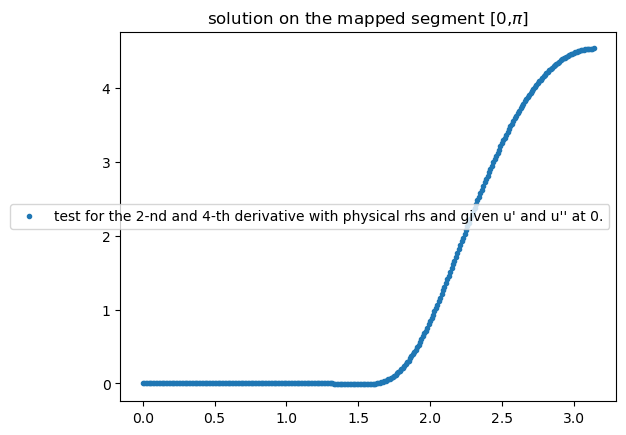

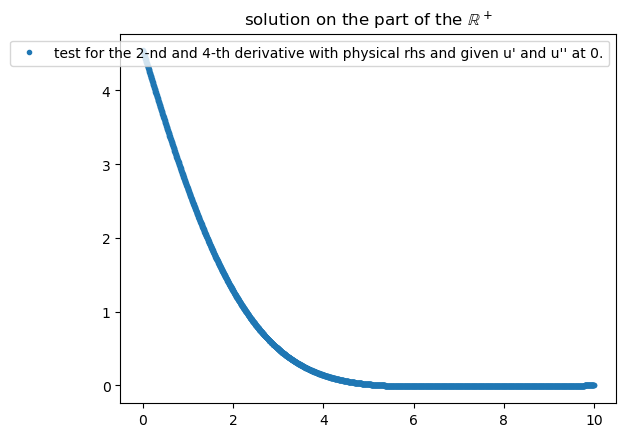

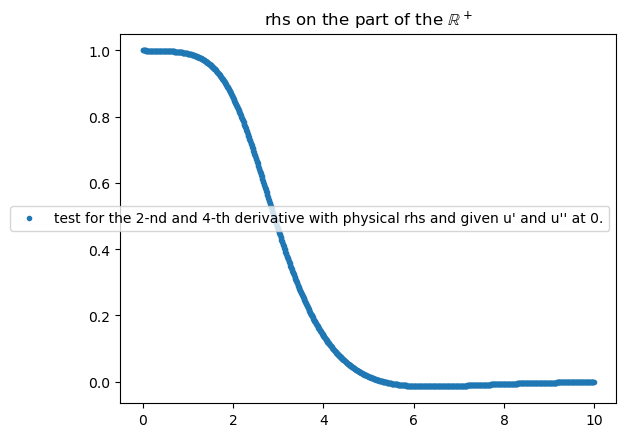

In [5]:
#testing a particular problem number
problem = all_problems[6]
problem.info()
problem.get_name()
solver.set_problem(problem)
c = solver.solve_problem()
plot_all(c, problem)

test for the 2-nd derivative with manufactured solution exp(-x) and discontinuous coefficient if(x<1,1,10).
$eps(x)u_{xx}=f(x,u)-g(x)$, $u=exp(-x)$
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=13.914s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=1.451386 elapsed=15.365s
[collocation/newton] solve_start norm=rms N=100 unknown_count=103 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.000s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.169305 elapsed=0.170s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.170s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=4.502842e-01 target_norm=1.014889e-09 elapsed=0.182s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=0e+00 res

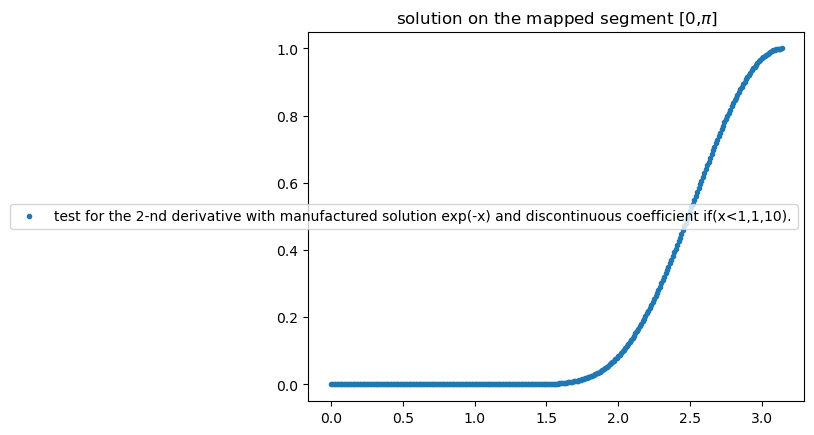

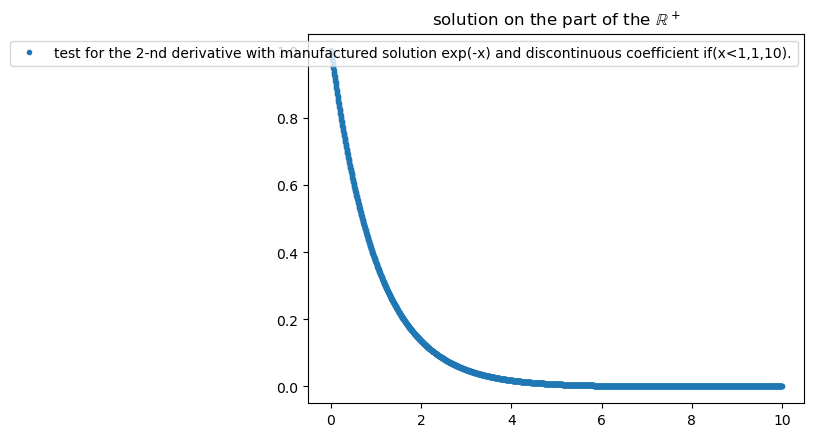

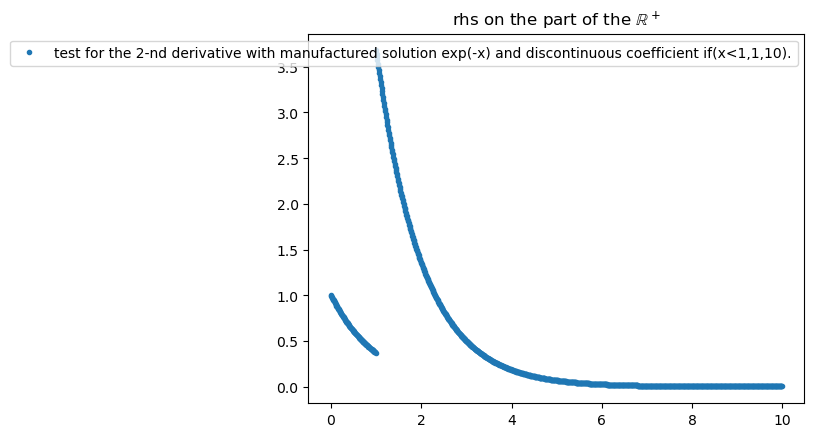

test for the 4-th derivative with manufactured solution exp(-x) and discontinuous coefficient if(x<1,1,10).
$eps(x)u_{xxxx}=f(x,u)-g(x)$, $u=exp(-x)$
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=1.438s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=2.469572 elapsed=3.908s
[collocation/newton] solve_start norm=rms N=100 unknown_count=103 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1697242 elapsed=0.170s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.171s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=3.473493e+02 target_norm=1.014889e-09 elapsed=0.183s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=0e+00 re

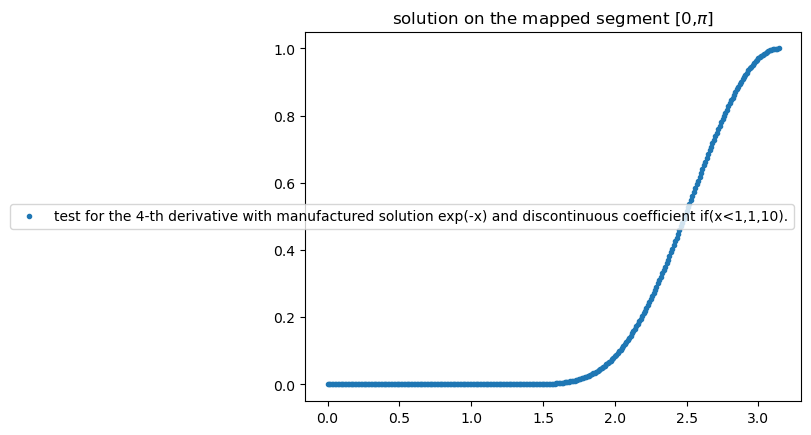

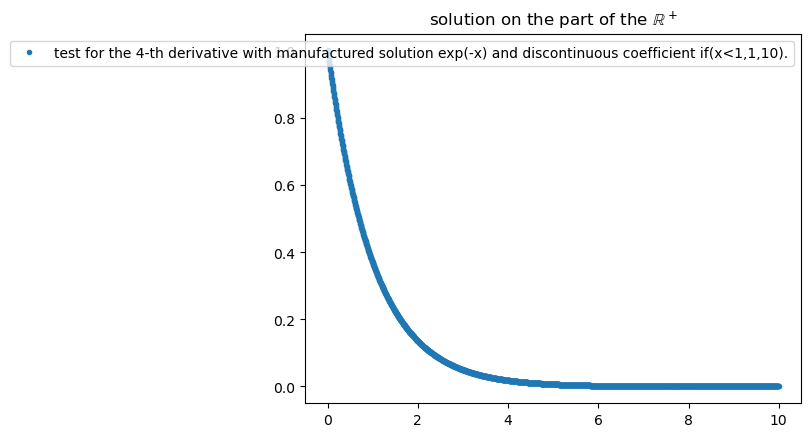

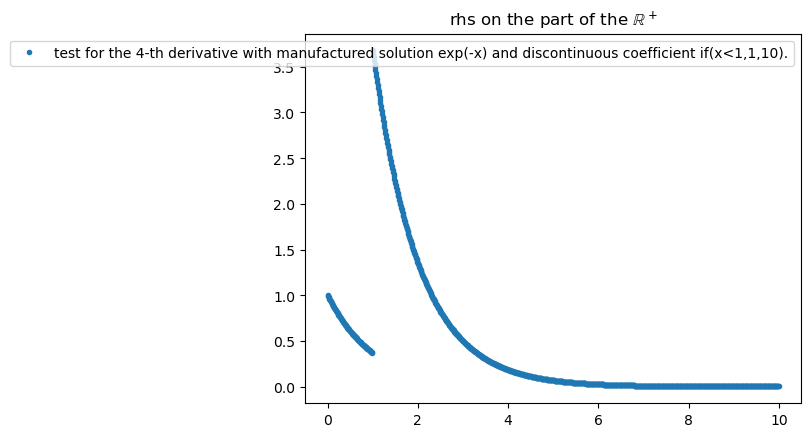

test for the 2-nd derivative with and discontinuous coefficient if(x<1,1,1000).
$eps(x)u_{xx}=sinh(u)$, $u=exp(-x)$
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=102 elapsed=1.446s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=102 success=yes duration=1.539259 elapsed=2.985s
[collocation/newton] solve_start norm=rms N=100 unknown_count=102 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1946575 elapsed=0.195s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.196s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=4.460517e+01 target_norm=1.00995e-09 elapsed=0.208s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=0e+00 residual_norm=4.460517e+01 target_nor

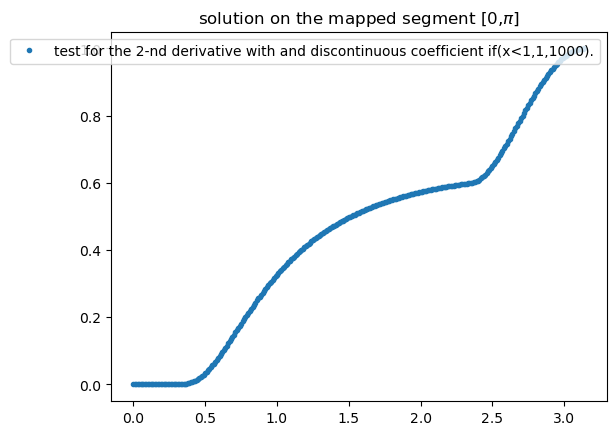

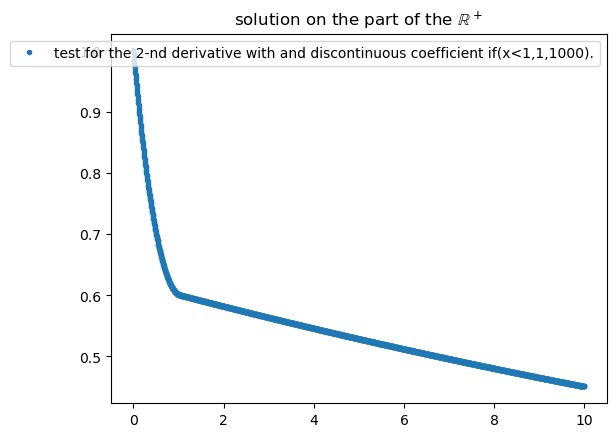

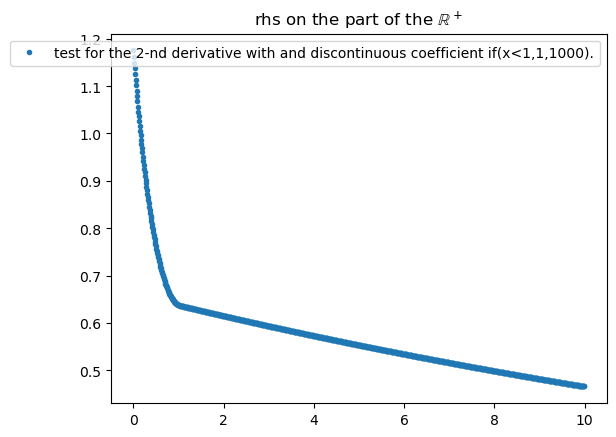

test for the 4-nd derivative with and discontinuous coefficient if(x<1,1,1000).
$eps(x)u_{xxxx}=sinh(u)$, $u=exp(-x)$
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=1.451s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=3.303507 elapsed=4.755s
[collocation/newton] solve_start norm=rms N=100 unknown_count=103 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1927357 elapsed=0.193s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.194s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=4.194556e+02 target_norm=1.014889e-09 elapsed=0.207s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=0e+00 residual_norm=4.194556e+02 target_

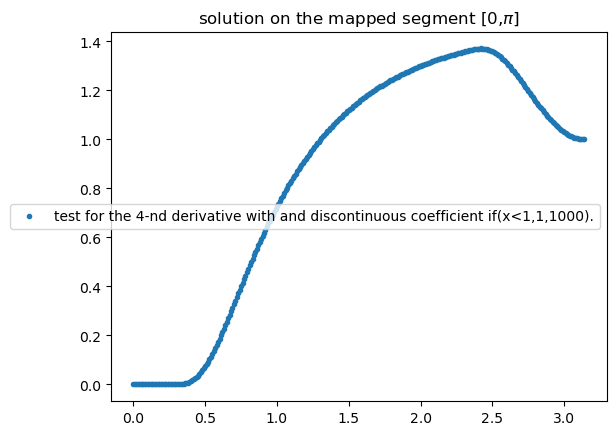

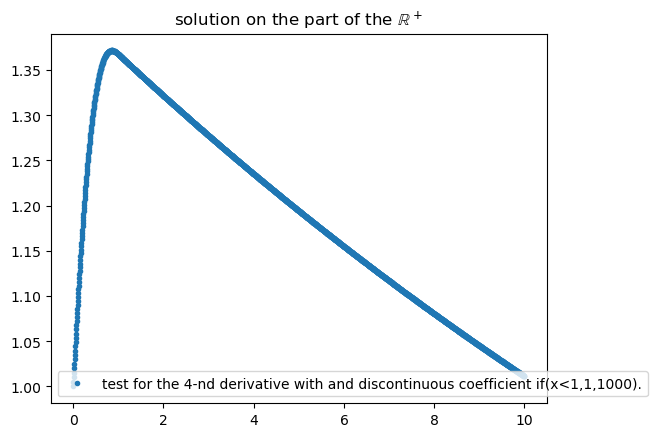

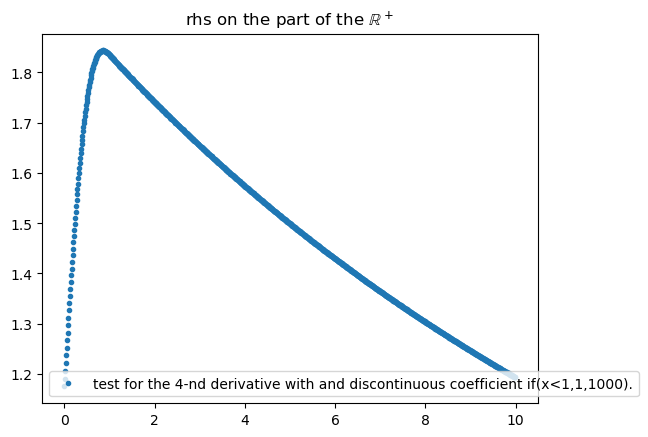

test for the 2-nd derivative with physical rhs and neumann BCs at 0.
$u_{xx}=f(x,u), f(x,u):=sinh(u)*sqrt(1+4/(1+cosh(u) )-1) from literature
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=102 elapsed=1.786s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=102 success=yes duration=0.8771164 elapsed=2.663s
[collocation/newton] solve_start norm=rms N=100 unknown_count=102 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1711822 elapsed=0.172s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.172s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=8.528072e+01 target_norm=1.00995e-09 elapsed=0.184s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=0e+00 residual_n

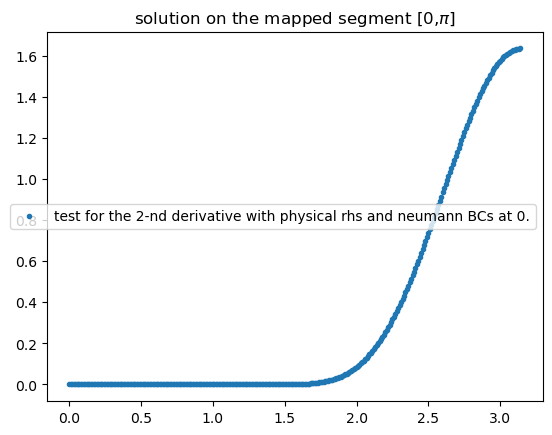

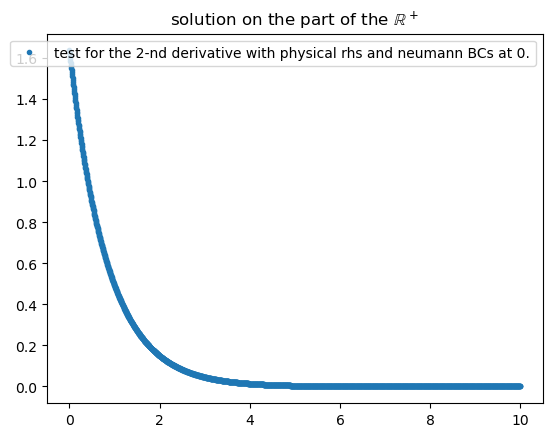

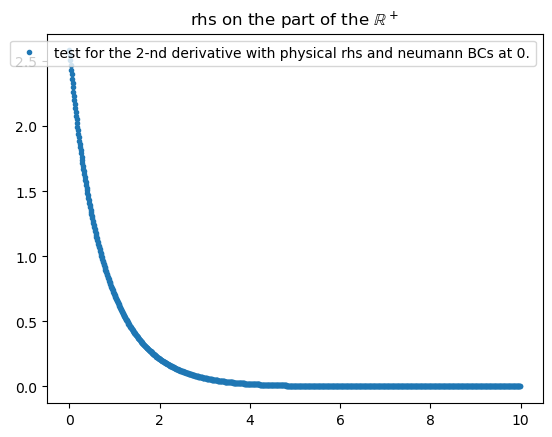

test for the 2-nd and 4-th derivative with physical rhs and given u' and u''' at 0.
$u_{xx}-u_{xxxx}=f(x,u), f(x,u):=sinh(u)*sqrt(1+sinh(u)^2) from literature
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=10.982s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=2.530536 elapsed=13.513s
[collocation/newton] solve_start norm=rms N=100 unknown_count=103 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1691391 elapsed=0.170s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.171s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=2.406632e+07 target_norm=1.014889e-09 elapsed=0.183s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homoto

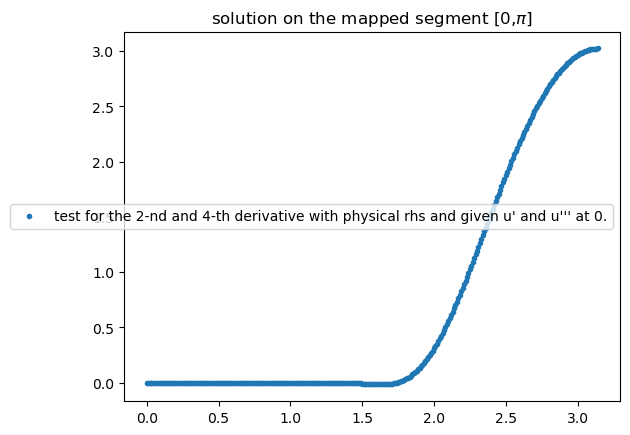

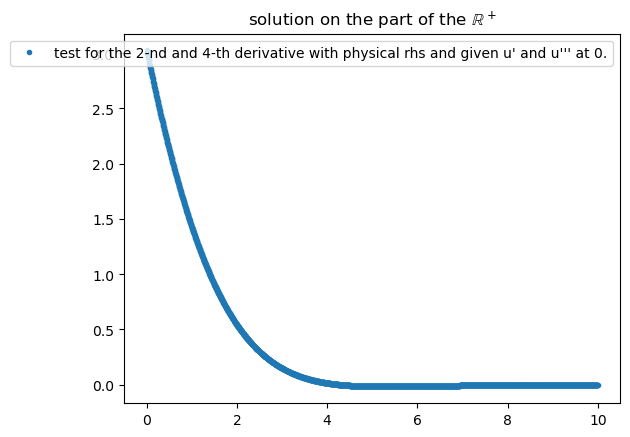

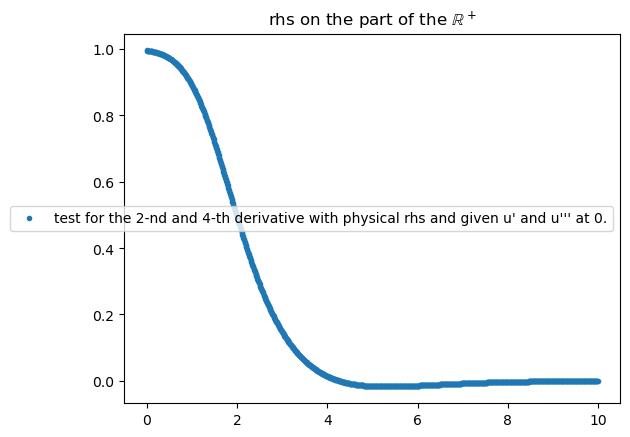

test for the 2-nd and 4-th derivative with physical rhs and given u' and u'' at 0.
$u_{xx}-u_{xxxx}=f(x,u), f(x,u):=sinh(u)*sqrt(1+sinh(u)^2) from literature
[collocation/newton] phase_start norm=rms phase=collocation_assembly N=100 unknown_count=103 elapsed=5.072s
[collocation/newton] phase_end norm=rms phase=collocation_assembly N=100 unknown_count=103 success=yes duration=2.548239 elapsed=7.620s
[collocation/newton] solve_start norm=rms N=100 unknown_count=103 arithmetic=numpy backend=numpy precision=15 elapsed=0.000s
[collocation/newton] phase_start norm=rms phase=initial_guess elapsed=0.001s
[collocation/newton] phase_end norm=rms phase=initial_guess success=yes duration=0.1738593 elapsed=0.175s
[collocation/newton] stage_start norm=rms stage=1 homotopy=0e+00 elapsed=0.175s
[collocation/newton] stage_residual norm=rms stage=1 homotopy=0e+00 residual_norm=1.193991e+08 target_norm=1.014889e-09 elapsed=0.188s
[collocation/newton] iteration_start norm=rms stage=1 iteration=1 homotopy=

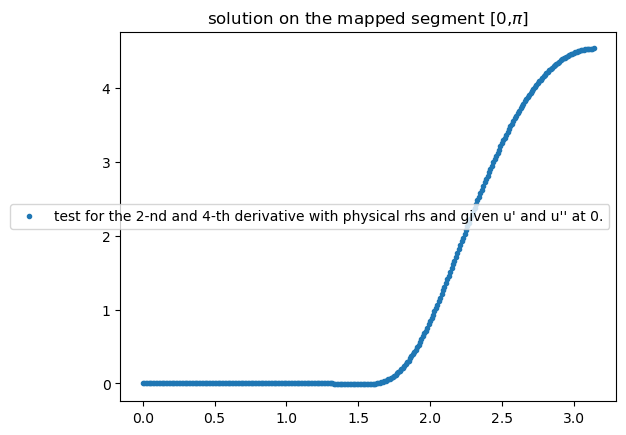

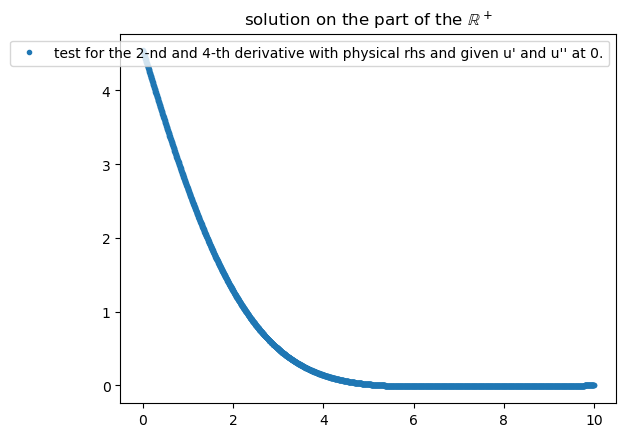

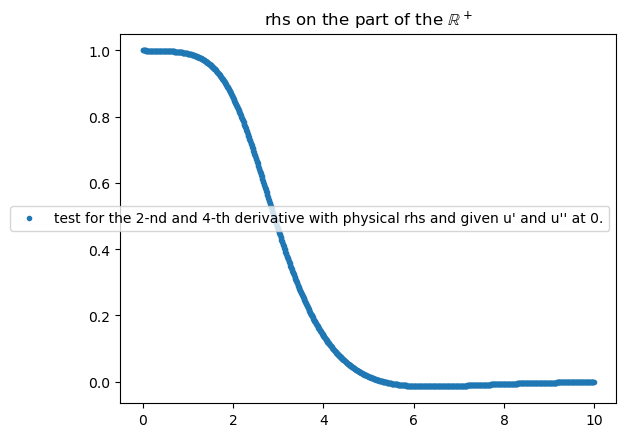

done.


In [6]:
#testing all problems
for problem in all_problems:
    print(problem.info())
    print(problem.get_name())
    solver.set_problem(problem)
    c = solver.solve_problem()
    plot_all(c, problem)
print("done.")